<a href="https://colab.research.google.com/github/dcryer2024/PyTorch/blob/main/PyTorch_CNN_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Notebook to practice building, training and testing a CNN architecture using PyTorch

In [25]:
# Import Relevant Modules and Datasets
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2

# Import plotting libraries
import matplotlib.pyplot as plt

# Import numpy for data storage
import numpy as np

# Import tensorboard requirements
!pip install tensorboard
from datetime import datetime
from torch.utils.tensorboard import SummaryWriter
from collections import defaultdict

run_name = datetime.now().strftime("%Y%m%d-%H%M%S")
writer = SummaryWriter(f"runs/lenet_{run_name}")   # new folder per run so runs can be compared

In [4]:
# Load the Datasets

# Training Data
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
)

# Test Data
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 13.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.03MB/s]


<class 'torchvision.tv_tensors._image.Image'> torch.Size([1, 28, 28])
<class 'int'> 9
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


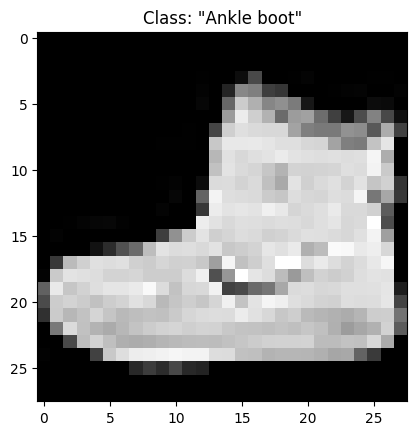

In [5]:
# Check an example datapoint from the training set
sample = training_data[0]
X_sample, y_sample = sample
print(type(X_sample), X_sample.shape)
print(type(y_sample), y_sample)
classes = training_data.classes
print(classes)

# Show the image
X_sample = X_sample.squeeze()
plt.imshow(X_sample, cmap="gray")
title = classes[y_sample]
plt.title(f'Class: "{title}"')
plt.show()

In [6]:
# Use the Dataloader wrapper to batch the datasets
batch_size = 64
training_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# Check the shape of the new object created
for X, y in training_dataloader:
  print(X.shape, y.shape)
  break


torch.Size([64, 1, 28, 28]) torch.Size([64])


In [29]:
# Use GPU if possible
import nvidia
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")
!nvidia-smi


# Define the architecture using nn.Module inheritance
# Inputs have been normalised, ReLU activation preveents vanishing gradients, and small network means that gradients unlikely to explode with proper weight initialisation
# For a ReLU network, Kaiming initialisation should be used to keep weights stable in the early stages
class CNN(nn.Module):
  def __init__(self):
    super().__init__()
    # Build the CNN section
    self.CNN_stack = nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=1),
        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=1),
    )
    # Build the fc section (no automatic flatten here)
    self.fc_stack = nn.Sequential(
        nn.Linear(in_features=64 * 7 * 7, out_features=128),
        nn.ReLU(),
        nn.Linear(in_features=128, out_features=10),
    )

  # Build the forward fucntion that joins both stacks
  def forward(self, x):
    x = self.CNN_stack(x)
    x = x.Flatten()
    logits = self.fc_stack(x)
    return logits


Using cuda device
Wed Oct 28 15:09:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             31W /   70W |     127MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------

In [66]:
# Build the model

# Specify the initialisation by running apply for each sub module (layers) in Sequential
def init_weights(model):
  if isinstance(model, (nn.Linear, nn.Conv2d)):
    nn.init.kaiming_normal_(model.weight, nonlinearity="relu")
    if model.bias is not None:
      nn.init.zeros_(model.bias)

# Build the model
model = CNN().to(device)
model.apply(init_weights)
print(model)


CNN(
  (CNN_stack): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_stack): Sequential(
    (0): Linear(in_features=3136, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [67]:
# Check that the Kaiming initialisation was applied
for param in model.parameters():
  if param.ndim == 1:
    print(f'mean over the {param.shape[0]} bias values is {param.mean().item()}')
  else:
    print(f'mean over the {param.numel()} weights is {param.mean().item()}')
    print(f'variance over the {param.numel()} weights is {param.var().item()}')

mean over the 288 weights is -0.02654934488236904
variance over the 288 weights is 0.19465310871601105
mean over the 32 bias values is 0.0
mean over the 18432 weights is -0.0003856831754092127
variance over the 18432 weights is 0.00702136754989624
mean over the 64 bias values is 0.0
mean over the 401408 weights is -8.327473915414885e-05
variance over the 401408 weights is 0.0006406349129974842
mean over the 128 bias values is 0.0
mean over the 1280 weights is 0.0023863872047513723
variance over the 1280 weights is 0.01568649522960186
mean over the 10 bias values is 0.0


In [68]:
# Specify the loss and optimizer settings
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3) # ADAM needs the model parameters as an input

In [69]:
# Write a train function
def train(dataloader, model, optimizer, loss_fn, writer, epoch, log_every=20):
    model.train()
    n_batches = len(dataloader)
    size = len(dataloader.datasets)

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        loss = loss_fn(model(X), y)                   # Calculate over the whole batch - X has 64 datapoints in it! Default is to take the mean over the batch
        loss.backward()

        step = epoch * n_batches + batch              # global step, continuous across epochs

        # Save the loss at regular intervals
        if batch % log_every == 0:
            writer.add_scalar("loss/train", loss.item(), step)

            # Save the norm of the gradients at each layer
            layer_sq = defaultdict(float)
            for name, p in model.named_parameters():
                if p.grad is not None:
                    layer = name.rsplit(".", 1)[0]                  # "cnn_model.0.weight" -> "cnn_model.0"
                    layer_sq[layer] += p.grad.norm().item() ** 2

            for layer, sq in layer_sq.items():
                writer.add_scalar(f"grad_norm_layer/{layer}", sq ** 0.5, step)

        # Printouts
        if batch % 100 == 0:                                            # "Every 100th batch index"
            loss, current = loss.item(), (batch + 1) * len(X)           # Current measures how many training samples have been processed this epoch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

        optimizer.step()

# Write a test function
def test(dataloader, model, loss_fn):
  model.eval()
  n_batches = len(dataloader)
  size = len(dataloader.datasets)
  test_loss, correct = 0

  with torch.no_grad():
    for batch, (X, y) in enumerate(dataloader):
      X, y = X.to(device), y.to(device)
      pred = model(X)
      loss = loss_fn(pred, y).item()
      correct += (pred.argmax(1) == y).type(torch.float).sum().item() # We need to sum over all the correct guesses in the batch here
      test_loss /= n_batches

    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [9]:
# Build an instance of the CNN class and train it
epochs = 5
for t in range(epochs):
  print(f"Epoch {t+1}\n-------------------------------")
  train(training_dataloader, model, optimizer, loss_fn, writer, t+1, 20)
  test(test_dataloader, model, loss_fn)
print("Done!")



# Use a specified weight initialisation upon constructuion of the model


# Save evaluation data during training runs

In [10]:
# Save the trained model weights
torch.save(model.state_dict(), "model.pth")
print("Saved PyTorch Model State to model.pth")

In [ ]:
# Load the trained model and test it
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

model.eval()                                                      # Change the mode to evaluation mode again

test_length = 5
for i in range(test_length):
  x, y = test_data[i][0], test_data[i][1]
  with torch.no_grad():
      x = x.to(device)
      pred = model(x)

      # Get the image ready
      img = x.to("cpu")
      img = img.squeeze()

      # Prediction distribution from the model
      probabilities = pred.softmax(dim=1).squeeze().cpu()

  predicted = probabilities.argmax().item()

  # Image on the left, probability bars on the right
  fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 3.5))

  ax_img.imshow(img, cmap="gray")
  ax_img.set_title(f'Actual: "{classes[y]}"')
  ax_img.axis("off")

  colours = ["tab:green" if j == predicted else "tab:blue" for j in range(len(classes))]
  ax_bar.barh(classes, probabilities.numpy(), color=colours)
  ax_bar.set_xlim(0, 1)
  ax_bar.invert_yaxis()                     # first class at the top
  ax_bar.set_xlabel("Probability")
  ax_bar.set_title(f'Predicted: "{classes[predicted]}" ({probabilities[predicted]:.1%})')

  plt.tight_layout()
  plt.show()